# Modelo base para predecir el abandono de clientes (Telco Churn)

**Curso:** TC5061 - **Actividad:** Notebook Baseline - **Alumno:** Oscar Gutiérrez - **Matrícula:** A00832992

## 1. Introducción

Una empresa de telecomunicaciones pierde clientes cada mes (churn). Si sabe quién está por irse, puede ofrecerle algo antes de que cancele. El objetivo de este notebook es construir un modelo base que prediga si un cliente abandonará el servicio y dejar el experimento registrado en MLflow para que sea reproducible.

### Configuración

Fijamos una semilla para que la división de datos y el modelo den siempre el mismo resultado.

In [1]:
# Librerías
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Ocultar mensajes informativos y avisos de MLflow que no afectan el resultado
logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning, module="mlflow")

# Semilla para reproducibilidad
SEED = 42
np.random.seed(SEED)

# Ruta del dataset
DATA_PATH = Path("data/Telco-Customer-Churn.csv")

# --- Estilo de gráficas: azul = se queda, naranja = abandona ---
COLOR_NO, COLOR_SI, COLOR_GRIS = "#2a78d6", "#eb6834", "#8a8985"
PALETA_CHURN = {"No": COLOR_NO, "Yes": COLOR_SI}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10,
})

## 2. Carga y descripción del dataset

Usamos el dataset Telco Customer Churn publicado por IBM (disponible en Kaggle). Cada fila es un cliente; las columnas describen sus datos demográficos, los servicios que contrató, cómo paga y si abandonó la empresa en el último mes.

In [2]:
# Carga del CSV y tamaño del dataset
df_raw = pd.read_csv(DATA_PATH)

print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 7,043 | Variables: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Tipo de dato, nulos y valores distintos por columna
estructura = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "valores_unicos": df_raw.nunique(),
    "ejemplo": df_raw.iloc[0],
})
estructura

,tipo,nulos,valores_unicos,ejemplo
customerID,str,0,7043,7590-VHVEG
gender,str,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,str,0,2,Yes
Dependents,str,0,2,No
tenure,int64,0,73,1
PhoneService,str,0,2,No
MultipleLines,str,0,3,No phone service
InternetService,str,0,3,DSL
OnlineSecurity,str,0,3,No


Diccionario de datos:

| Variable | Tipo | Significado |
|---|---|---|
| `customerID` | Texto | Identificador único del cliente |
| `gender` | Categórica | Género (Male, Female) |
| `SeniorCitizen` | Binaria (0/1) | El cliente tiene 65 años o más |
| `Partner` | Categórica | Tiene pareja |
| `Dependents` | Categórica | Tiene dependientes económicos |
| `tenure` | Numérica | Meses que lleva como cliente |
| `PhoneService` | Categórica | Tiene servicio telefónico |
| `MultipleLines` | Categórica | Tiene varias líneas telefónicas |
| `InternetService` | Categórica | Tipo de internet: DSL, Fiber optic o No |
| `OnlineSecurity` | Categórica | Contrató seguridad en línea |
| `OnlineBackup` | Categórica | Contrató respaldo en línea |
| `DeviceProtection` | Categórica | Contrató protección de equipos |
| `TechSupport` | Categórica | Contrató soporte técnico |
| `StreamingTV` | Categórica | Contrató TV por streaming |
| `StreamingMovies` | Categórica | Contrató películas por streaming |
| `Contract` | Categórica | Plazo del contrato: mensual, 1 año o 2 años |
| `PaperlessBilling` | Categórica | Recibe factura electrónica |
| `PaymentMethod` | Categórica | Método de pago |
| `MonthlyCharges` | Numérica | Cargo mensual actual (USD) |
| `TotalCharges` | Texto (debería ser numérica) | Total cobrado desde el alta (USD) |
| `Churn` | Categórica (variable objetivo) | El cliente abandonó en el último mes (Yes/No) |

El dataset tiene 7,043 clientes y 21 variables: 1 identificador, 3 numéricas, 16 categóricas y la variable objetivo. No hay nulos, pero `TotalCharges` aparece como texto cuando debería ser un número, y `SeniorCitizen` aparece como número cuando es categórica.

## 3. Análisis exploratorio

Para poder graficar `TotalCharges` la convertimos a número en una copia de los datos. El tratamiento formal está en la sección 4.

In [4]:
# Copia para el EDA con TotalCharges numérica (las celdas en blanco quedan como NaN)
eda = df_raw.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")

# Listas de variables numéricas y categóricas
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = [c for c in df_raw.columns if c not in NUM_COLS + ["customerID", "Churn"]]

### 3.1 Estadísticas descriptivas

In [5]:
# Variables numéricas: estadísticas descriptivas y asimetría
desc_num = eda[NUM_COLS].describe().T
desc_num["asimetria"] = eda[NUM_COLS].skew()
desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96


In [6]:
# Variables categóricas: número de categorias, categoria más frecuente y su frecuencia
eda[CAT_COLS + ["Churn"]].astype(str).describe().T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,0,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


- `tenure` va de 0 a 72 meses, con una mediana de 29. Hay muchos clientes nuevos y muchos muy antiguos.
- `MonthlyCharges` va de 18 a 119 USD, con una mediana de 70.
- `TotalCharges` tiene asimetría positiva (0.96): la media (2,283) está muy por encima de la mediana (1,397). La mayoría acumula poco y unos pocos acumulan mucho. Además, solo tiene 7,032 valores: 11 faltantes que estaban ocultos como texto.
- Las categóricas tienen entre 2 y 4 niveles.

### 3.2 Variable objetivo

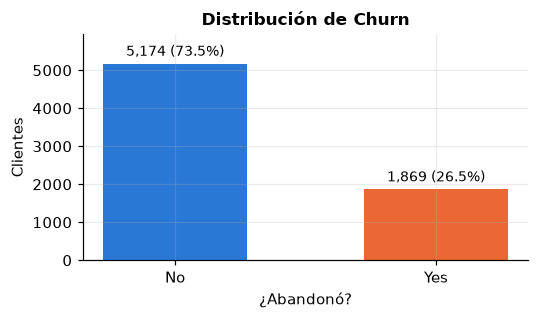

In [7]:
# Balance de clases de Churn
conteo = eda["Churn"].value_counts()
proporcion = eda["Churn"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(5, 3))
barras = ax.bar(conteo.index, conteo.values, color=[PALETA_CHURN[k] for k in conteo.index], width=0.55)
for barra, n, p in zip(barras, conteo.values, proporcion.values):
    ax.annotate(f"{n:,} ({p:.1%})", (barra.get_x() + barra.get_width() / 2, n),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set(title="Distribución de Churn", xlabel="¿Abandonó?", ylabel="Clientes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout(); plt.show()

Las clases están desbalanceadas: 73.5 % se queda y 26.5 % abandona, así que un modelo que siempre diga "No" acierta el 73.5 % de las veces sin aprender nada. Por eso:

1. La división entrenamiento/prueba será estratificada, para conservar esta proporción en ambos conjuntos.
2. El accuracy no basta. Evaluaremos también recall, precision, F1 y ROC-AUC.

### 3.3 Distribución de las variables numéricas

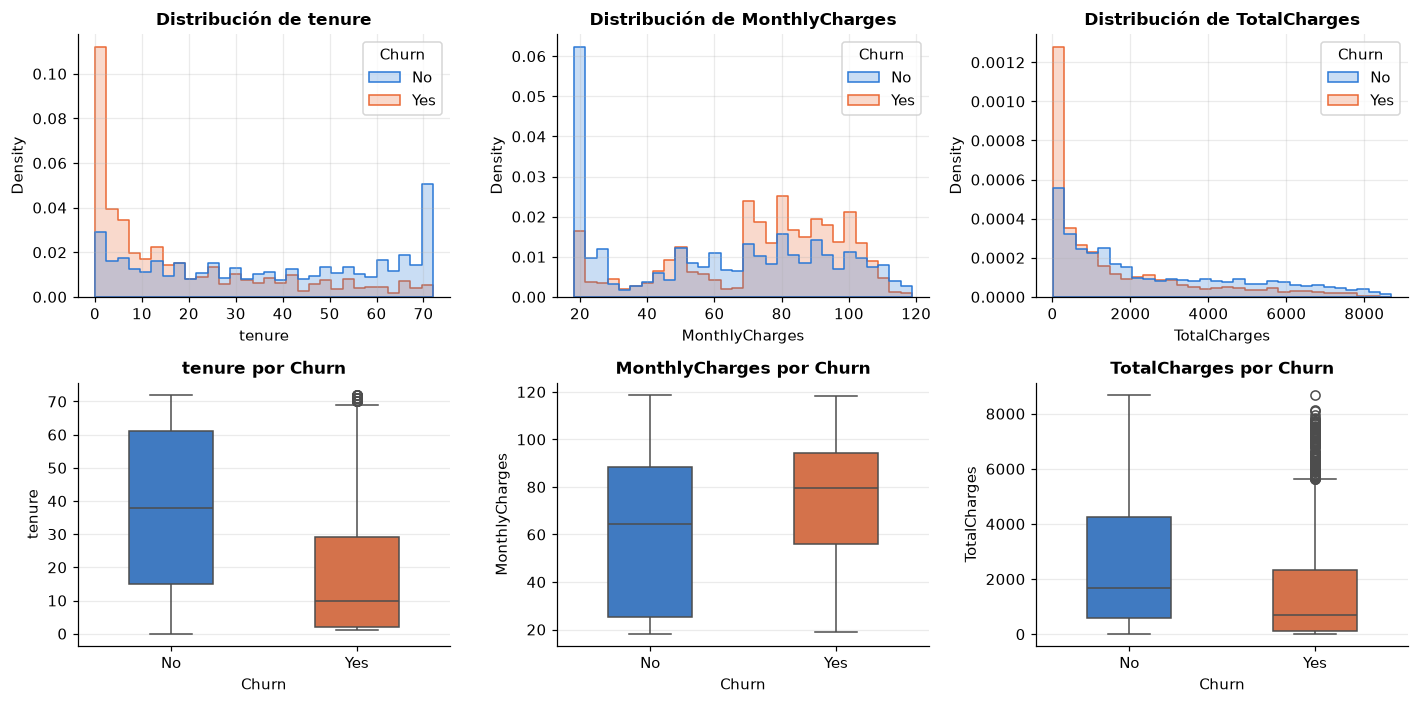

In [8]:
# Histogramas (arriba) y boxplots (abajo) de cada variable numérica, separados por Churn
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for i, col in enumerate(NUM_COLS):
    sns.histplot(data=eda, x=col, hue="Churn", hue_order=["No", "Yes"], palette=PALETA_CHURN,
                 bins=30, element="step", stat="density", common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(data=eda, x="Churn", y=col, hue="Churn", order=["No", "Yes"], palette=PALETA_CHURN,
                width=0.45, ax=axes[1, i], legend=False)
    axes[1, i].set_title(f"{col} por Churn")
plt.tight_layout(); plt.show()

- `tenure`: quienes abandonan son clientes recientes (mediana de 10 meses, contra 38 de quienes se quedan). El riesgo se concentra en los primeros meses.
- `MonthlyCharges`: quienes abandonan pagan más al mes (mediana de 80 USD contra 64 USD). Los cargos altos empujan a cancelar.
- `TotalCharges`: es menor en quienes abandonan, porque llevan menos tiempo. Depende de `tenure` × `MonthlyCharges`, así que aporta poca información nueva.
- En los boxplots de quienes abandonan aparecen outliers en `tenure` y `TotalCharges`.

### 3.4 Tasa de abandono por variable categórica

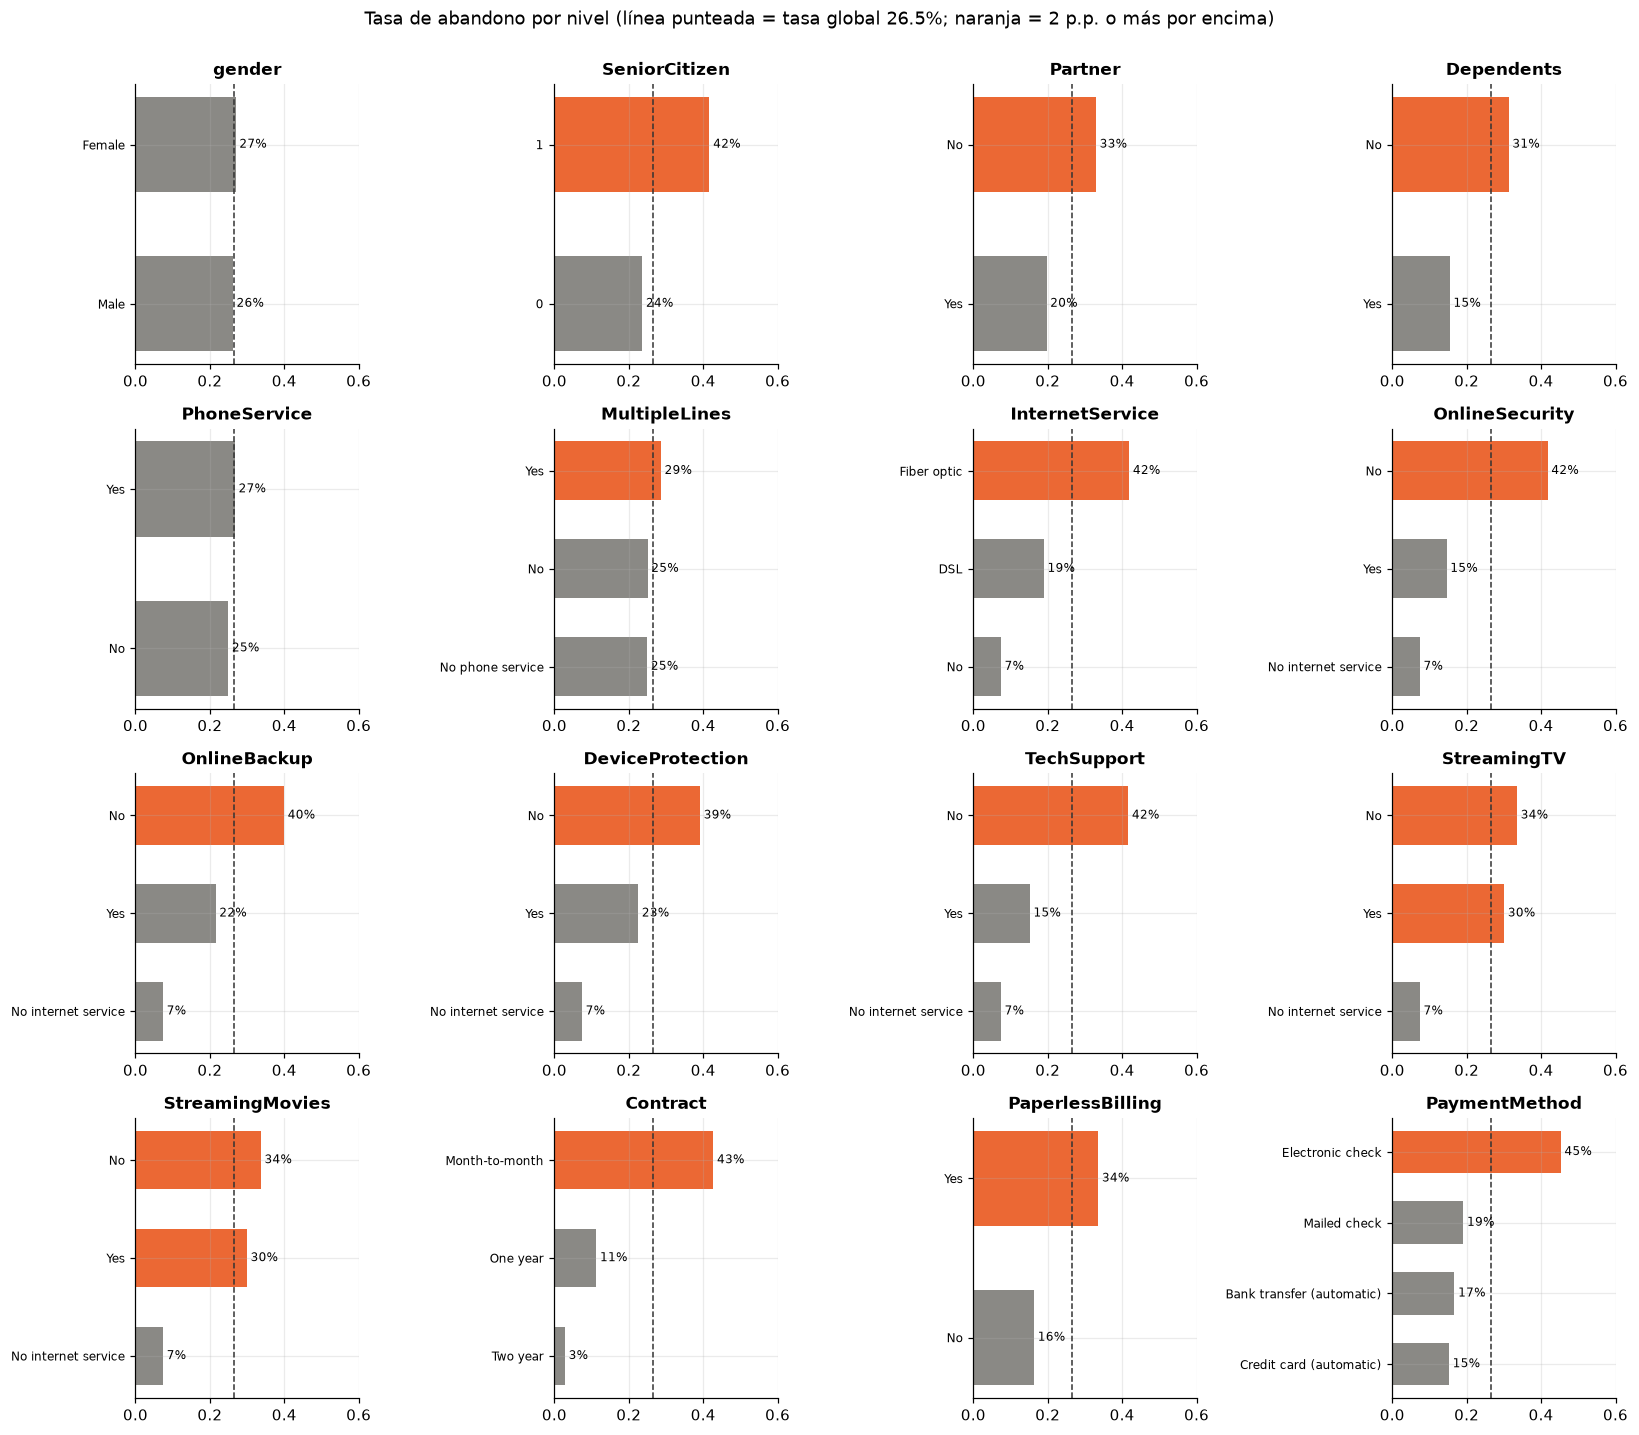

In [9]:
# Tasa de abandono en cada nivel de cada variable categórica, comparada con la tasa global
tasa_global = (eda["Churn"] == "Yes").mean()
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for ax, col in zip(axes.flat, CAT_COLS):
    tasa = (eda.assign(churn=eda["Churn"].eq("Yes"))
               .groupby(col)["churn"].mean().sort_values())
    colores = [COLOR_SI if t > tasa_global + 0.02 else COLOR_GRIS for t in tasa.values]
    ax.barh(tasa.index.astype(str), tasa.values, color=colores, height=0.6)
    ax.axvline(tasa_global, color="#333", ls="--", lw=1)
    for y, t in enumerate(tasa.values):
        ax.text(t + 0.01, y, f"{t:.0%}", va="center", fontsize=8)
    ax.set_xlim(0, 0.6); ax.set_title(col); ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"Tasa de abandono por nivel (línea punteada = tasa global {tasa_global:.1%}; naranja = 2 p.p. o más por encima)",
             fontsize=12, y=1.0)
plt.tight_layout(); plt.show()

- `Contract` es la variable más fuerte: con contrato mensual abandona ≈ 43 %; con contrato de 2 años, ≈ 3 %.
- `InternetService`: con fibra óptica abandona ≈ 42 %, más que con DSL (≈ 19 %). Puede ser por precio o por la calidad del servicio.
- `PaymentMethod`: con "Electronic check" abandona ≈ 45 %; con pagos automáticos, ≈ 15–17 %.
- Servicios de soporte (`OnlineSecurity`, `TechSupport`): quienes tienen internet y no los contrataron abandonan ≈ 42 %, casi el triple que quienes sí (≈ 15 %).
- Sin internet (`No internet service`), la tasa baja a ≈ 7 %.
- `gender`, `PhoneService` y `MultipleLines` casi no cambian la tasa (25–29 %). Es probable que aporten poco al modelo.
- `SeniorCitizen = 1` (42 %), `Partner = No` (33 %), `Dependents = No` (31 %) y `PaperlessBilling = Yes` (34 %) suben el riesgo.

### 3.5 Relaciones entre variables

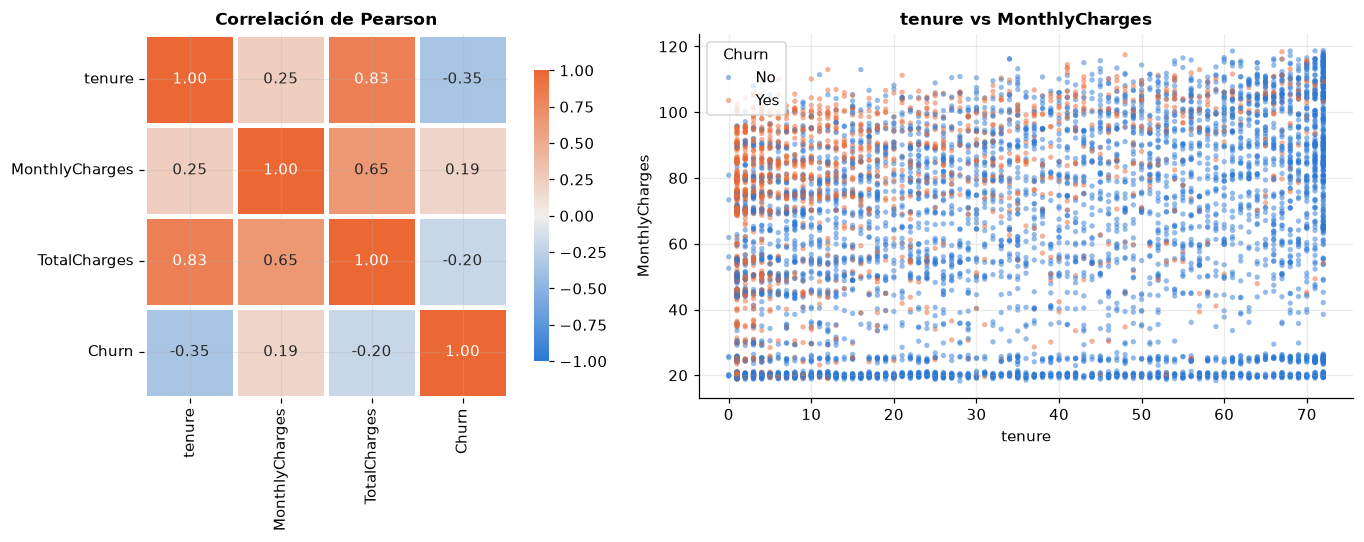

In [10]:
# Correlación entre numéricas y la variable objetivo codificada como 0/1
corr = eda[NUM_COLS].assign(Churn=eda["Churn"].eq("Yes").astype(int)).corr()
cmap_div = LinearSegmentedColormap.from_list("azul_naranja", [COLOR_NO, "#f0efec", COLOR_SI])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap_div, vmin=-1, vmax=1, square=True,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title("Correlación de Pearson")

# Dispersión tenure vs MonthlyCharges: dónde se concentran los que abandonan
sns.scatterplot(data=eda.sample(frac=1, random_state=SEED), x="tenure", y="MonthlyCharges",
                hue="Churn", hue_order=["No", "Yes"], palette=PALETA_CHURN, s=12, alpha=0.5,
                linewidth=0, ax=axes[1])
axes[1].set_title("tenure vs MonthlyCharges")
plt.tight_layout(); plt.show()

- `TotalCharges` tiene una correlación de 0.83 con `tenure` y de 0.65 con `MonthlyCharges`. Para un modelo lineal esto es colinealidad.
- `tenure` tiene la correlación más fuerte con `Churn` y es negativa (−0.35): a más antigüedad, menos abandono. `MonthlyCharges` la tiene positiva (0.19).
- En la gráfica de dispersión, los puntos naranjas se agrupan arriba a la izquierda: clientes nuevos con cargos altos. Ese es el perfil de mayor riesgo.

### 3.6 Conclusiones del EDA

1. El problema es de clasificación binaria con clases desbalanceadas (26.5 % positivos).
2. Las señales más fuertes son el tipo de contrato, la antigüedad, el tipo de internet, el método de pago y los servicios de soporte.
3. Problemas de calidad a resolver: `TotalCharges` con tipo incorrecto y faltantes ocultos, `SeniorCitizen` codificada como número, `customerID` sin valor predictivo y una posible redundancia en `TotalCharges`.

## 4. Limpieza de datos

In [11]:
# Copia de trabajo para la limpieza; df_raw queda intacto
df = df_raw.copy()

### 4.1 Tipos de dato incorrectos

In [12]:
# Evidencia: TotalCharges no se puede convertir a número por completo
total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
no_convertibles = df.loc[total_num.isna(), "TotalCharges"]
print(f"TotalCharges no convertibles: {len(no_convertibles)} -> valores distintos: {sorted(set(map(repr, no_convertibles)))}")
print(f"SeniorCitizen valores: {sorted(df['SeniorCitizen'].unique())} (tipo {df['SeniorCitizen'].dtype})")

TotalCharges no convertibles: 11 -> valores distintos: ["' '"]
SeniorCitizen valores: [np.int64(0), np.int64(1)] (tipo int64)


- `TotalCharges` se leyó como texto porque 11 celdas están en blanco. La convertimos a `float` porque es un monto en dólares y, como texto, no se puede escalar ni usar en el modelo. Las celdas en blanco quedan como `NaN` y se tratan en la sección 4.2.
- `SeniorCitizen` viene como `int` 0/1, pero es categórica. La convertimos a `"No"`/`"Yes"` para que sea consistente con las demás variables binarias (`Partner`, `Dependents`).

In [13]:
# Corrección de tipos
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df[["TotalCharges", "SeniorCitizen"]].dtypes

TotalCharges     float64
SeniorCitizen        str
dtype: object

### 4.2 Valores faltantes

In [14]:
# los faltantes aparecen solo después de convertir TotalCharges
print("Nulos por columna (solo > 0):")
print(df.isna().sum()[lambda s: s > 0])
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Nulos por columna (solo > 0):
TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Los 11 faltantes tienen `tenure = 0`. Son clientes que acaban de darse de alta y todavía no reciben su primera factura: el sistema no tenía nada que cobrar.

Imputamos `TotalCharges = 0` porque es el valor real para un cliente sin facturas. Eliminar las filas quitaría a los clientes nuevos, el grupo de mayor riesgo, y usar la media o la mediana les asignaría cobros de miles de dólares que nunca pagaron.

In [15]:
# Imputación con 0 y verificación
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
assert df.isna().sum().sum() == 0
print("Nulos restantes:", df.isna().sum().sum())

Nulos restantes: 0


### 4.3 Duplicados

In [16]:
# duplicados exactos, IDs repetidos y duplicados ignorando el ID
print(f"Filas duplicadas exactas:          {df.duplicated().sum()}")
print(f"customerID repetidos:              {df['customerID'].duplicated().sum()}")
dup_sin_id = df.drop(columns="customerID").duplicated(keep=False)
print(f"Filas idénticas ignorando el ID:   {dup_sin_id.sum()} (incluye ambas copias)")
df.loc[dup_sin_id].drop(columns="customerID").sort_values(["tenure", "MonthlyCharges"]).head(6)

Filas duplicadas exactas:          0
customerID repetidos:              0
Filas idénticas ignorando el ID:   42 (incluye ambas copias)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
5170,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
6774,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
4817,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.90,No
6706,Female,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.90,No


- No hay filas duplicadas exactas ni `customerID` repetidos.
- Si ignoramos el ID, 42 filas coinciden con al menos otra. Todas tienen `tenure = 1` y planes estándar (26 de ellas sin internet). Un cliente de un mes que contrata el paquete básico tiene pocas formas de ser distinto a otro, así que es normal que dos personas tengan el mismo perfil.
- Conservamos todas las filas: son clientes distintos (ID diferente), no errores de captura, y eliminarlas quitaría observaciones reales.

### 4.4 Valores atípicos (outliers)

In [17]:
# Regla IQR: atípico si está fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
def resumen_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"min": serie.min(), "lim_inf": lim_inf, "lim_sup": lim_sup, "max": serie.max(),
                      "n_outliers": int(((serie < lim_inf) | (serie > lim_sup)).sum())})

df[NUM_COLS].apply(resumen_iqr).T.round(2)

,min,lim_inf,lim_sup,max,n_outliers
tenure,0.00,-60.00,124.00,72.00,0.0
MonthlyCharges,18.25,-46.02,171.38,118.75,0.0
TotalCharges,0.00,-4683.52,8868.67,8684.80,0.0


- Con la regla IQR no hay outliers en ninguna variable numérica. Todos los valores están dentro de rangos posibles: `tenure` de 0 a 72 meses y cargos de 18 a 119 USD al mes.
- Los puntos fuera de los bigotes de la sección 3.3 solo aparecen al separar por clase: son clientes antiguos que abandonaron, un grupo pequeño pero válido. En la distribución completa están dentro del rango.
- La asimetría de `TotalCharges` no es un error: refleja clientes con mucha antigüedad.

### 4.5 Consistencia de categorías

In [18]:
# Niveles de cada categórica: espacios sobrantes, mayúsculas inconsistentes o errores de escritura
for col in CAT_COLS + ["Churn"]:
    niveles = df[col].unique().tolist()
    con_espacios = [n for n in niveles if n != n.strip()]
    print(f"{col:<17} {niveles}" + (f"  <- espacios: {con_espacios}" if con_espacios else ""))

gender            ['Female', 'Male']
SeniorCitizen     ['No', 'Yes']
Partner           ['Yes', 'No']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No phone service', 'No', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'Yes', 'No internet service']
OnlineBackup      ['Yes', 'No', 'No internet service']
DeviceProtection  ['No', 'Yes', 'No internet service']
TechSupport       ['No', 'Yes', 'No internet service']
StreamingTV       ['No', 'Yes', 'No internet service']
StreamingMovies   ['No', 'Yes', 'No internet service']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['Yes', 'No']
PaymentMethod     ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn             ['No', 'Yes']


- No hay espacios sobrantes ni variantes de escritura.
- Seis variables de internet tienen el nivel `"No internet service"`, y `MultipleLines` tiene `"No phone service"`. Son redundantes con `InternetService = "No"` y `PhoneService = "No"`.
- Los conservamos como nivel propio: "no tiene el servicio porque no tiene internet" es distinto de "tiene internet y no contrató el servicio". El one-hot encoding los maneja sin problema.

### 4.6 Columnas irrelevantes y codificación de la variable objetivo

In [19]:
# customerID no tiene valor predictivo; Churn pasa a 0/1 (1 = abandona, la clase de interés)
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
print(f"Dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head(3)

Dataset limpio: 7,043 filas x 20 columnas


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


### 4.7 Resumen de la limpieza

Convertimos `TotalCharges` a número e imputamos con 0 sus 11 valores faltantes, que correspondían a clientes con `tenure = 0`. Pasamos `SeniorCitizen` a `"No"`/`"Yes"`, eliminamos `customerID` y codificamos `Churn` como 0/1. No encontramos duplicados exactos ni outliers, y conservamos tanto los 42 perfiles idénticos con ID distinto como los niveles redundantes de las variables de servicios.

El dataset final tiene 7,043 filas y 20 columnas (19 predictoras y la objetivo), sin nulos y con tipos correctos.

## 5. Modelo base

### 5.1 Elección del modelo

Usamos dos modelos. El primero es un `DummyClassifier` que siempre predice la clase más frecuente ("No"). Sirve como piso de referencia: cualquier modelo útil debe superarlo. El segundo, el modelo base, es una `LogisticRegression`. Es el modelo estándar para clasificación binaria: es rápido, no tiene hiperparámetros delicados, entrega probabilidades y sus coeficientes se pueden interpretar.

Usamos la configuración por defecto (`C = 1.0`, regularización L2, umbral 0.5). Ajustar el modelo es trabajo de etapas posteriores.

### 5.2 División entrenamiento / prueba

- 80 % entrenamiento / 20 % prueba, con `stratify=y` para conservar el 26.5 % de abandono en ambos conjuntos.
- `random_state=42` para que la división sea reproducible.

In [20]:
# Separación de predictoras y objetivo, y división estratificada
X = df.drop(columns="Churn")
y = df["Churn"]
TEST_SIZE = 0.2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

print(f"Entrenamiento: {X_train.shape[0]:,} filas | churn = {y_train.mean():.1%}")
print(f"Prueba:        {X_test.shape[0]:,} filas | churn = {y_test.mean():.1%}")

Entrenamiento: 5,634 filas | churn = 26.5%
Prueba:        1,409 filas | churn = 26.5%


### 5.3 Pipeline de preprocesamiento + modelo

El preprocesamiento va dentro del `Pipeline`. Así, el escalador y el codificador se ajustan solo con los datos de entrenamiento y no hay fuga de datos del conjunto de prueba.

- Numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`) → `StandardScaler`.
- Categóricas (16) → `OneHotEncoder`. Con `drop="if_binary"` las binarias quedan en una sola columna, y con `handle_unknown="ignore"` las categorías nuevas no rompen la predicción.

In [21]:
# Definición de columnas para el preprocesamiento
num_cols = NUM_COLS
cat_cols = [c for c in X.columns if c not in num_cols]

preprocesamiento = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

# Modelo base: regresión logística con parámetros por defecto
LOGREG_PARAMS = {"C": 1.0, "solver": "lbfgs", "max_iter": 1000}  # regularización L2 por defecto
modelo_base = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(**LOGREG_PARAMS, random_state=SEED)),
])

# Referencia mínima: siempre predice la clase mayoritaria
modelo_dummy = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", DummyClassifier(strategy="most_frequent")),
])

modelo_base.fit(X_train, y_train)
modelo_dummy.fit(X_train, y_train)
modelo_base

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

## 6. Evaluación

### 6.1 Métricas

Como la clase de interés es la minoritaria (abandona = 1), la accuracy no basta: con clases desbalanceadas, un modelo puede acertar mucho sin detectar a quienes abandonan. Además de la accuracy, calculamos la precision (de los clientes que el modelo marca como "abandona", cuántos sí abandonan), el recall (de los que sí abandonan, cuántos detecta), el F1 (la media armónica de las dos, que usamos como métrica principal) y el ROC-AUC (qué tan bien ordena a los clientes por riesgo, sin depender del umbral).

In [22]:
# Cálculo de métricas para entrenamiento y prueba
def calcular_metricas(modelo, X_, y_):
    pred = modelo.predict(X_)
    proba = modelo.predict_proba(X_)[:, 1]
    return {
        "accuracy": accuracy_score(y_, pred),
        "precision": precision_score(y_, pred, zero_division=0),
        "recall": recall_score(y_, pred),
        "f1": f1_score(y_, pred),
        "roc_auc": roc_auc_score(y_, proba),
    }

resultados = {}
for nombre, modelo in [("Dummy", modelo_dummy), ("LogisticRegression", modelo_base)]:
    resultados[(nombre, "train")] = calcular_metricas(modelo, X_train, y_train)
    resultados[(nombre, "test")] = calcular_metricas(modelo, X_test, y_test)

tabla_metricas = pd.DataFrame(resultados).T.round(3)
tabla_metricas.index.names = ["modelo", "conjunto"]
tabla_metricas

accuracy  precision  recall     f1  roc_auc
modelo             conjunto                                             
Dummy              train        0.735      0.000   0.000  0.000    0.500
                   test         0.735      0.000   0.000  0.000    0.500
LogisticRegression train        0.806      0.661   0.550  0.600    0.849
                   test         0.806      0.657   0.559  0.604    0.842

### 6.2 Matriz de confusión y curva ROC

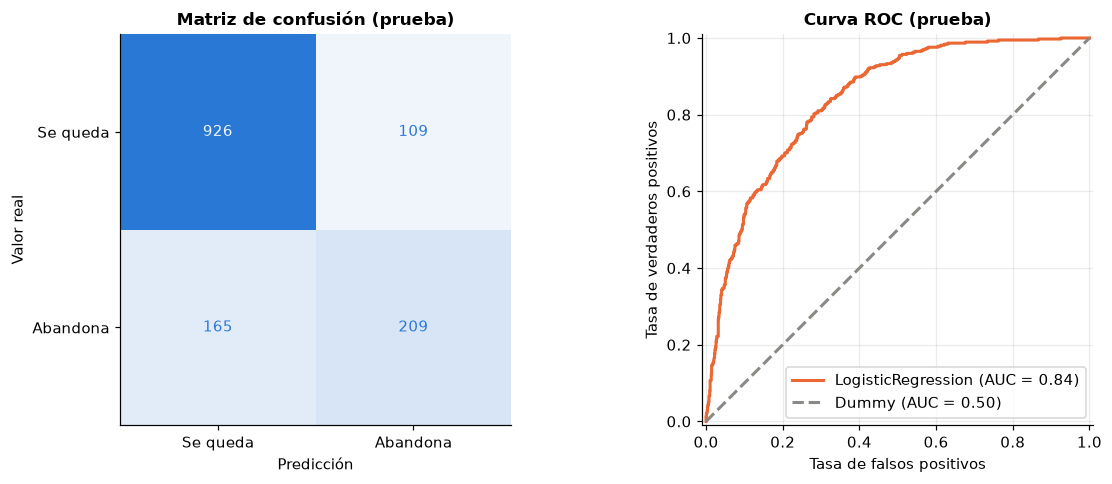

VN=926  FP=109  FN=165  VP=209


In [23]:
# Matriz de confusión y curva ROC en el conjunto de prueba
cmap_seq = LinearSegmentedColormap.from_list("azules", ["#f0f5fc", COLOR_NO])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

ConfusionMatrixDisplay.from_estimator(modelo_base, X_test, y_test, display_labels=["Se queda", "Abandona"],
                                      cmap=cmap_seq, colorbar=False, ax=axes[0])
axes[0].set(title="Matriz de confusión (prueba)", xlabel="Predicción", ylabel="Valor real"); axes[0].grid(False)

RocCurveDisplay.from_estimator(modelo_base, X_test, y_test, name="LogisticRegression",
                               curve_kwargs={"color": COLOR_SI, "lw": 2}, ax=axes[1])
RocCurveDisplay.from_estimator(modelo_dummy, X_test, y_test, name="Dummy",
                               curve_kwargs={"color": COLOR_GRIS, "lw": 2, "ls": "--"}, ax=axes[1])
axes[1].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = pd.crosstab(y_test, modelo_base.predict(X_test)).values.ravel()
print(f"VN={tn}  FP={fp}  FN={fn}  VP={tp}")

### 6.3 Variables más influyentes

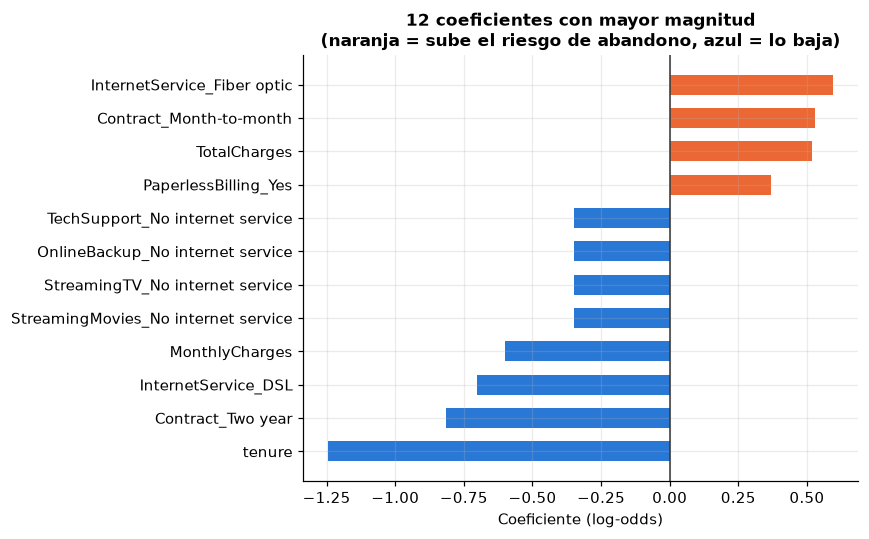

In [24]:
# Coeficientes de la regresión logística (sobre variables estandarizadas / one-hot)
nombres = modelo_base.named_steps["preprocesamiento"].get_feature_names_out()
coefs = pd.Series(modelo_base.named_steps["clasificador"].coef_[0], index=nombres)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([n.split("__")[1] for n in top.index], top.values,
        color=[COLOR_SI if v > 0 else COLOR_NO for v in top.values], height=0.6)
ax.axvline(0, color="#333", lw=1)
ax.set(title="12 coeficientes con mayor magnitud\n(naranja = sube el riesgo de abandono, azul = lo baja)",
       xlabel="Coeficiente (log-odds)")
plt.tight_layout(); plt.show()

### 6.4 Interpretación

El `DummyClassifier` obtiene 73.5 % de accuracy sin detectar a un solo cliente que abandona (recall = 0, ROC-AUC = 0.50). La regresión logística sube la accuracy a 80.6 %. Son solo 7 puntos más, y por eso la accuracy no sirve para juzgar este problema. La diferencia real está en las demás métricas: el Dummy obtiene 0 en todas, y la regresión logística obtiene 0.657 de precision, 0.559 de recall, 0.604 de F1 y 0.842 de ROC-AUC.

De los 318 clientes que el modelo marca como "abandona", 209 sí abandonan (2 de cada 3). De los 374 clientes que abandonan, detecta 209 y se le escapan 165 (44 %). El ROC-AUC de 0.84 significa que, si tomamos al azar un cliente que abandona y uno que se queda, el modelo le da más riesgo al primero en el 84 % de los casos.

Las métricas de entrenamiento y prueba son casi iguales (ROC-AUC 0.849 contra 0.842; F1 0.600 contra 0.604), así que el modelo no está sobreajustado.

El error que más importa son los falsos negativos: para la empresa, no detectar a un cliente que se va (FN = 165) cuesta más que ofrecerle un descuento a quien no pensaba irse (FP = 109). Con el umbral por defecto de 0.5, el modelo es conservador: prefiere no marcar. Bajar el umbral o usar `class_weight="balanced"` subiría el recall a cambio de precision. La curva ROC muestra que ese margen existe.

Los coeficientes coinciden con el EDA: la antigüedad (`tenure`) y el contrato de 2 años bajan el riesgo; la fibra óptica, el contrato mensual y la factura electrónica lo suben.

En resumen, el modelo base ordena bien a los clientes por riesgo (ROC-AUC = 0.84), pero con el umbral actual deja escapar a casi la mitad de los que abandonan. Es un punto de partida válido. Las siguientes mejoras deben medirse contra él: ajustar el umbral según el costo de cada error, eliminar la colinealidad de `TotalCharges` y probar modelos no lineales.

## 7. Registro en MLflow

Registramos un run por modelo en el experimento `telco-churn-baseline`. Cada run guarda:

- Parámetros: modelo, hiperparámetros, tamaño de la prueba, semilla y estratificación.
- Métricas: las 5 métricas en entrenamiento y prueba.
- Artefacto: el pipeline completo (preprocesamiento + modelo), listo para cargarse y predecir.

In [25]:
# Backend local en SQLite; los artefactos se guardan en ./mlruns
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("telco-churn-baseline")

PARAMS_SPLIT = {"test_size": TEST_SIZE, "random_state": SEED, "stratify": True}

def registrar_run(nombre, modelo, params_modelo):
    """Registra parámetros, métricas y el modelo en un run de MLflow."""
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params({"modelo": nombre, **PARAMS_SPLIT, **params_modelo})
        for conjunto in ["train", "test"]:
            mlflow.log_metrics({f"{conjunto}_{k}": v for k, v in resultados[(nombre, conjunto)].items()})
        firma = infer_signature(X_train, modelo.predict(X_train))
        mlflow.sklearn.log_model(modelo, name="modelo", signature=firma)

registrar_run("Dummy", modelo_dummy, {"strategy": "most_frequent"})
registrar_run("LogisticRegression", modelo_base, LOGREG_PARAMS)

### Evidencia: experimento en la interfaz de MLflow

Run `LogisticRegression` del experimento `telco-churn-baseline` con sus 10 métricas de entrenamiento y prueba.

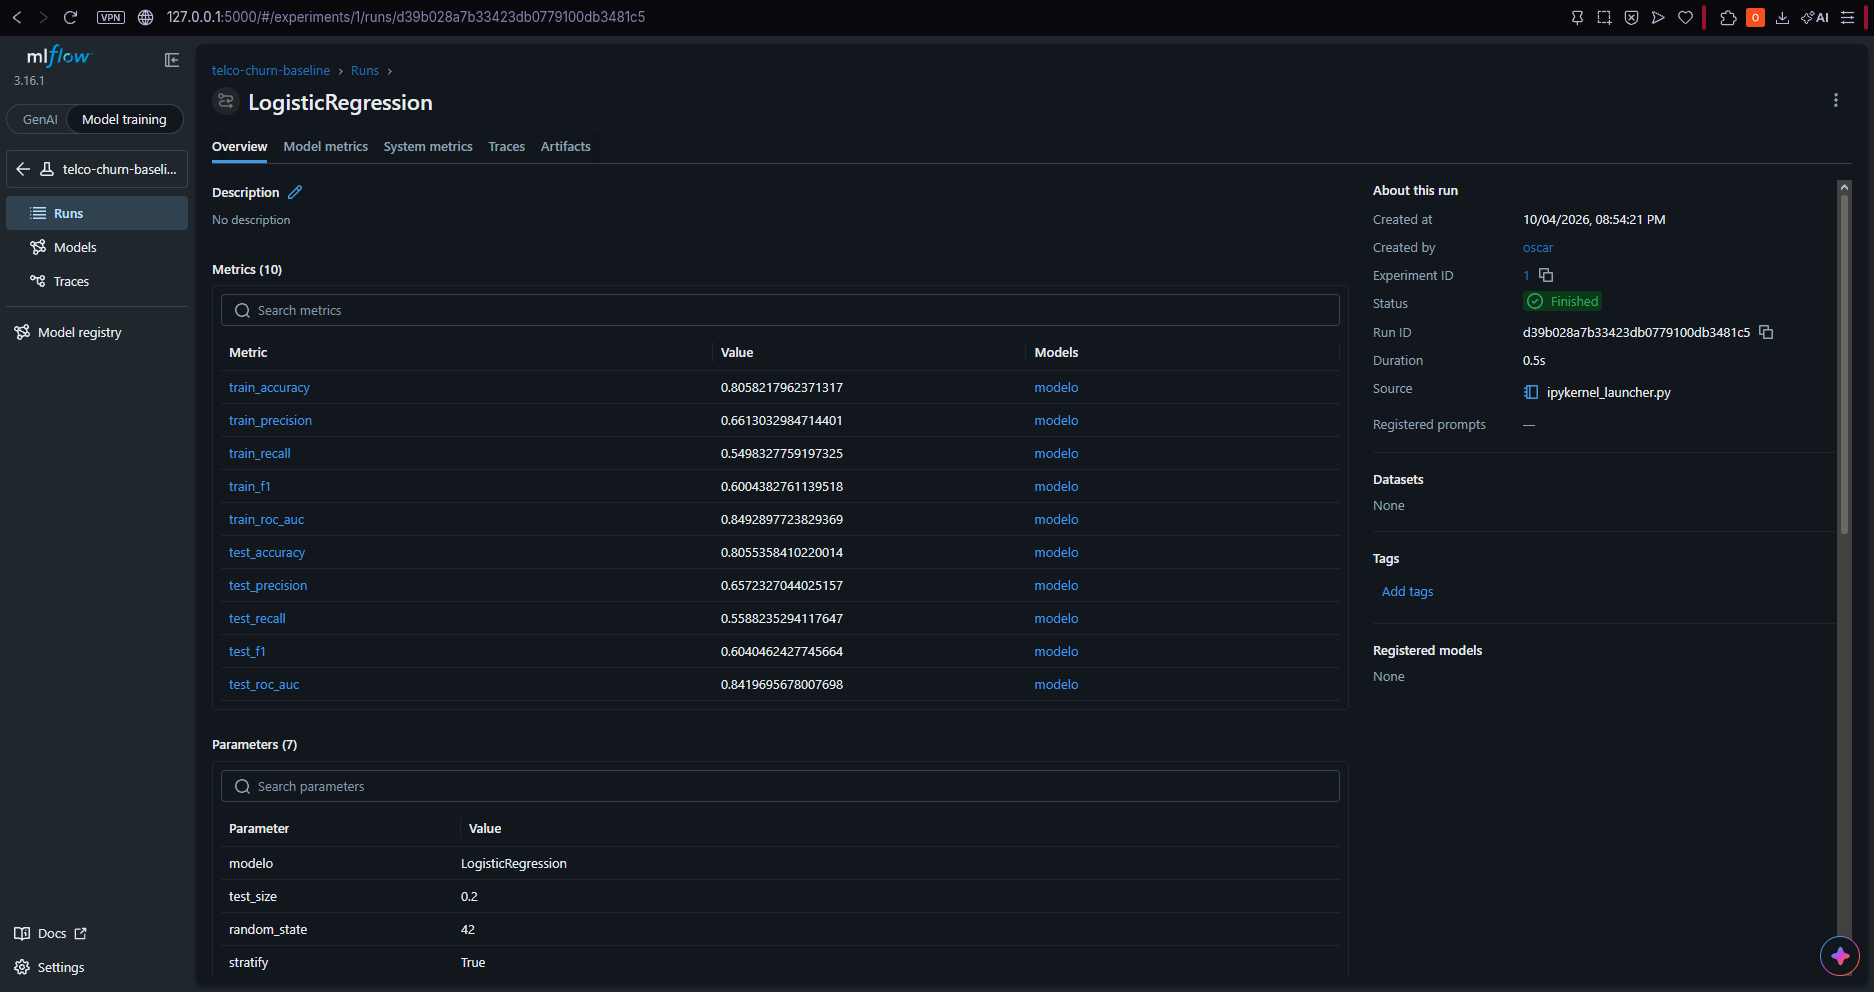

Mismo run: los 7 parámetros y el modelo guardado como artefacto.

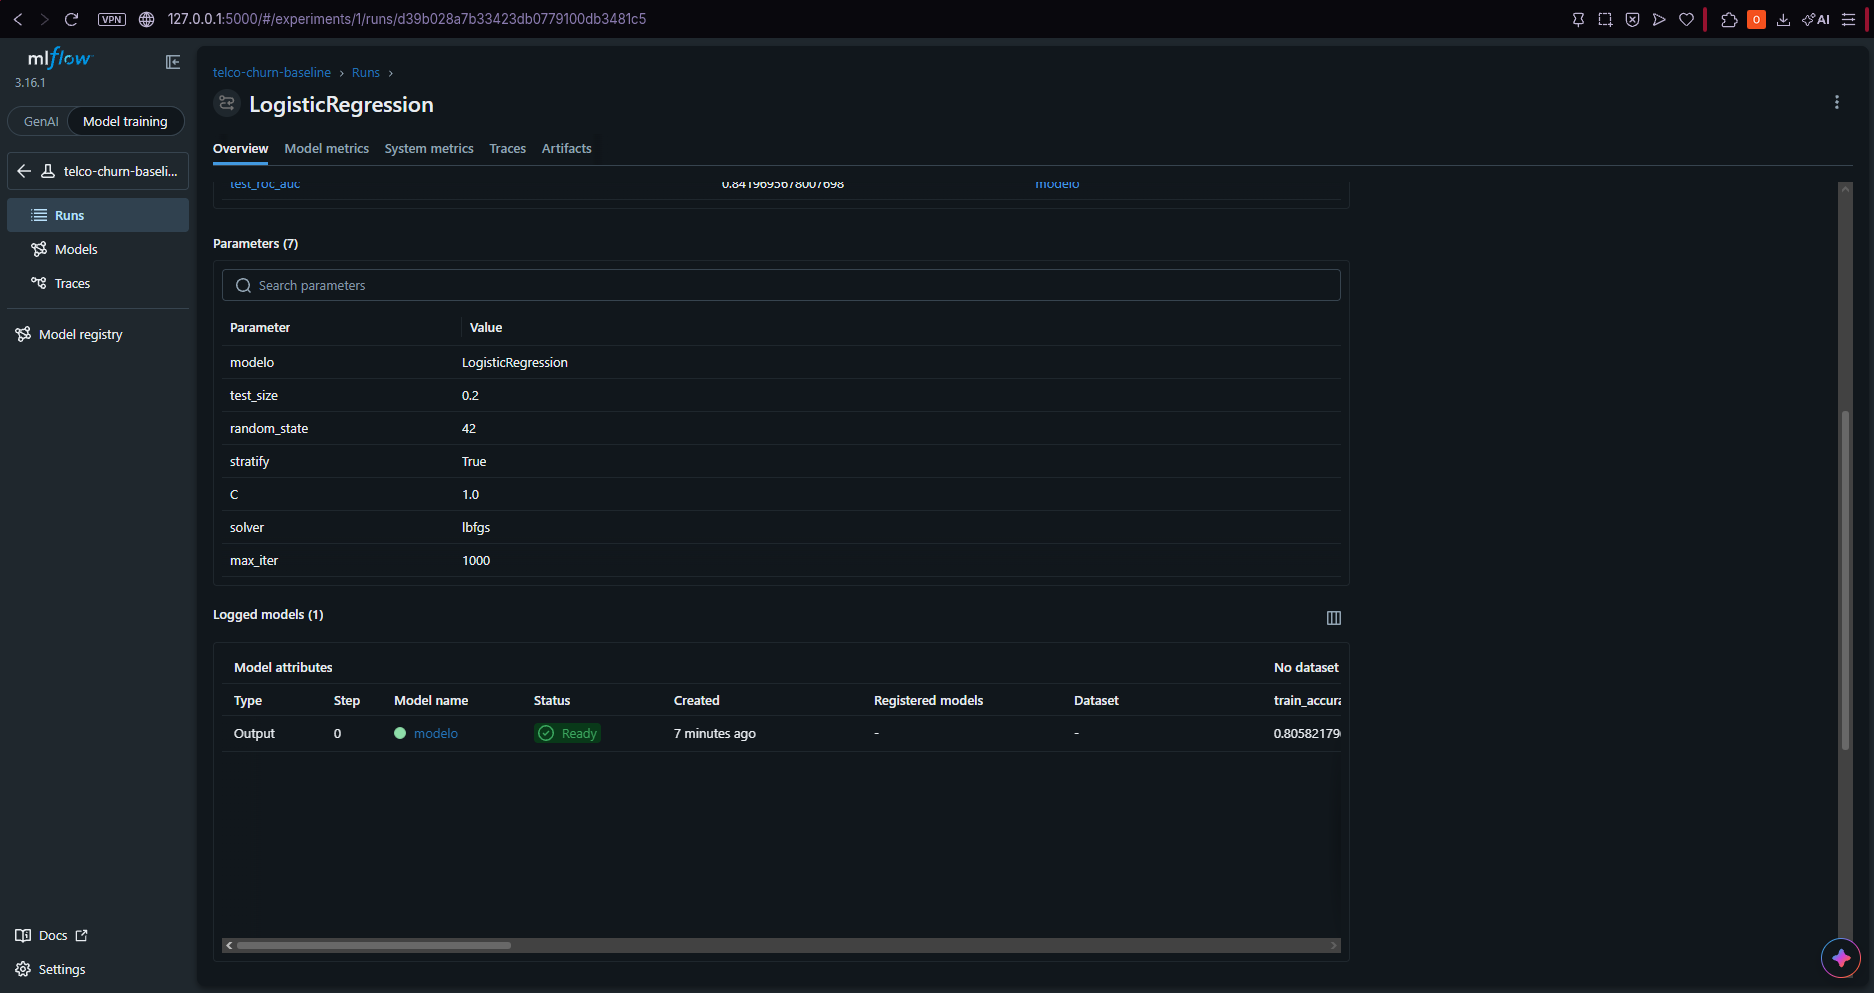

## 8. Reflexión sobre MLOps

### ¿Qué mejoraría aplicando prácticas de MLOps y por qué?

Este notebook funciona, pero depende de que alguien lo ejecute a mano, en orden y con el mismo archivo. Estos son los puntos que mejoraría:

1. Versionar los datos. Hoy nada garantiza que el CSV sea el mismo entre ejecuciones. Con DVC, cada versión del CSV quedaría ligada a un commit y a un run de MLflow, y cualquiera podría recuperar los datos exactos con los que se entrenó.
2. Convertir el notebook en un pipeline. Separar la carga, la limpieza, el entrenamiento y la evaluación en etapas independientes. Cada etapa se volvería a ejecutar solo si cambian sus entradas, y el resultado ya no dependería del orden de las celdas.
3. Validar la calidad de los datos automáticamente. Las reglas de la limpieza (sin nulos, `tenure` ≥ 0, solo niveles conocidos) deberían ser pruebas que detengan el pipeline si un archivo nuevo no las cumple. Hoy solo se revisan a ojo.

### ¿Cómo se reflejan estos aprendizajes en mi área profesional?

En proyectos en los que he trabajado nos ha pasado repetir un experimento porque nadie recordaba que ya se había probado, o porque los resultados estaban en el notebook de alguien más y no había forma de saber con qué datos ni con qué parámetros se obtuvieron. Eso cuesta tiempo y, a veces, termina en conclusiones distintas sin que nadie sepa por qué. Un registro como el de MLflow resuelve ese problema directamente: antes de correr algo, cualquiera del equipo puede revisar qué se intentó, con qué configuración y qué resultado dio. Lo primero que aplicaría en un proyecto nuevo es registrar cada experimento para que las mejoras se comparen contra algo medido y no contra lo que alguien recuerda.